# Korpus aufbauen

In [825]:
import os

corpus = [] #initial empty list

os.getcwd() #get current path

data_folder = os.path.join(os.getcwd(), "korpus") #join current path with directory name
print(list(os.walk(data_folder))) #check files inside of chosen directory

for root, folders, files in os.walk(data_folder): #structure of list is root -> folders -> files
    for file in files:
        path = os.path.join(root, file)
        with open(path, encoding="utf8") as input: #encode in utf8 for special characters like ä.ü,ö,ß
            corpus.append(input.read()) #append every file as new list-item
input.close()

print(len(corpus),"Texte wurden erfolgreich in den Korpus geladen.")


[('c:\\workspace\\nlp-lernen\\korpus', [], ['aanrud-sidsel_langroeckchen.txt', 'achleitner-Im_gruenen_Tann.txt', 'achleitner-Unter_den_Hohen_Tauern.txt', 'alarcon-Der Dreispitz.txt', 'alberti-Japanische Märchen.txt', 'anonymous-Der Luftpirat und sein lenkbares Luftschiff 40.txt', 'anonymous-Der Luftpirat und sein lenkbares Luftschiff 42.txt', 'anonymous-Der Luftpirat und sein lenkbares Luftschiff 56.txt', 'anonymous-Der Luftpirat und sein lenkbares Luftschiff 63.txt', 'goethe-faust1.txt', 'goethe-faust2.txt', 'kafka-landarzt.txt', 'kafka-urteil.txt', 'kafka-verwandlung.txt', 'schiller-raeuber.txt', 'Skowronnek-Sturmzeichen.txt', 'westermann-Die Nutzpflanzen unserer Kolonien und ihre wirtschaftliche Bedeutung für das Mutterland.txt'])]
17 Texte wurden erfolgreich in den Korpus geladen.


In [826]:
import nltk
from nltk.text import Text
from nltk.tokenize import word_tokenize
from nltk.probability import FreqDist
from nltk.util import ngrams
from nltk.tokenize import word_tokenize
from collections import Counter
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import cosine_distances, cosine_similarity
import numpy as np
import spacy
from textstat.textstat import textstatistics
import pyphen
import re

corpus_list = []
#corpus_vec = []
corpus_name = []

def number_words(text):
    text_words = re.findall(r'\b\w+\b', text.lower()) #regex um alle wörter zu finden und Satzzeichenzu entfernen; außerdem lower den Text
    return len(text_words)

def avg_word_len(text):
    text_words = re.findall(r'\b\w+\b', text.lower()) #regex um alle wörter zu finden und Satzzeichenzu entfernen; außerdem lower den Text
    avg_word_len = sum(len(word) for word in text_words) / len(text_words)
    return round(avg_word_len,1)

def number_sentences(text):
    sentences = nltk.sent_tokenize(text) #tokenize in sentences
    return len(sentences)

def avg_sen_len(text):
    avg_sen_len = round(number_words(text) / number_sentences(text),1) #average sentence length
    return avg_sen_len

#Type-Token-Ratio (TTR)
def ttr(tokens):
    return len(set(tokens)) / len(tokens) if tokens else 0 #make set without duplicates and divide with all tokens (incl. duplicates); if list is empty, dont divide with 0 just say, its 0

def punctuations(tokens):
    excl = 0
    quest = 0
    pct = 0
    com = 0
    semic = 0
    colo = 0

    for i in tokens:
        if i == "!":
            excl += 1
        if i == "?":
            quest += 1
        if i == ".":
            pct += 1
        if i == ",":
            com += 1
        if i == ";":
            semic += 1
        if i == ":":
            colo += 1

    erg_excl = excl / len(tokens)
    erg_quest = quest / len(tokens)
    erg_pct = pct / len(tokens)
    erg_com = com / len(tokens)
    erg_semic = semic / len(tokens)
    erg_colo = colo / len(tokens)

    return erg_excl, erg_quest, erg_pct, erg_com, erg_semic, erg_colo

def syllables_count(text, sprache='de_DE'):
    dic = pyphen.Pyphen(lang=sprache)
    worte = text.split()
    #print(worte)
    silben_gesamt = 0
    global syll1
    syll1 = 0
    
    for wort in worte:
        silben = dic.inserted(wort).split('-')
        #print(silben, len(silben))
        if len(silben) == 1:
            syll1 += 1
            #print("Silbe hier:",len(silben),"---->",silben)
        silben_gesamt += len(silben)

    return silben_gesamt

def avg_syllables_per_word(var3):
    #print("Übermittel var3:",var3)
    words = re.findall(r'\b\w+\b', var3.lower())
    avg_syllables = syllables_count(var3) / len(words)
    #print("Silben:",syllables_count(var3))
    #print("Wörter:",len(words))
    return round(avg_syllables, 1)

def flesch_reading_ease_ger(asl, asw):
    
    fre = 180 - asl - (58.5 - asw)
    
    return round(fre,2)

def wiener_sachtext_formel(text):
    syll = 0
    ms = 0 
    sl = 0
    iw = 0
    es = 0
    words6 = 0
    global syll1

    if syllables_count(text) > 3:
        syll += 1
    ms = syll / number_words(text) * 100
    sl = avg_sen_len(text)

    words = re.findall(r'\b\w+\b', text.lower())
    for word in words:
        if len(word) > 5:
            #print("hier:",len(word),"---->",word)
            words6 += 1
    iw = words6 / number_words(text)
    es = syll1 / number_words(text) * 100
    # print("MS:",ms)
    # print("SL:",sl)
    # print("SL:",sl)
    # print("IW:",iw)
    # print("ES:",es)

    # print("syll1:",syll1)
    # print("# Words:",number_words(text))
    #print("Formel: 0.1935 *", ms,"+ 0.1672 *", sl,"+ 0.1297 *", iw,"- 0.0327 *", es," - 0.875")

    wsf = 0.1935 * ms + 0.1672 * sl + 0.1297 * iw - 0.0327 * es - 0.875
    return round(wsf,2)

def ngram_haeufigkeit(text):
    # Kleinbuchstaben & Tokenisierung
    tokens = word_tokenize(text.lower())

    # Bigramme & Trigramme erzeugen
    bigramme = list(ngrams(tokens, 2))
    trigramme = list(ngrams(tokens, 3))

    # Häufigkeiten zählen
    bigram_haeufigkeit = Counter(bigramme)
    trigram_haeufigkeit = Counter(trigramme)

    # Ergebnisse anzeigen
    print(f"Anzahl eindeutiger Bigramme: {len(bigram_haeufigkeit)}")
    print(f"Anzahl eindeutiger Trigramme: {len(trigram_haeufigkeit)}\n")

    print("Top 5 Bigramme:")
    for bigram, count in bigram_haeufigkeit.most_common(5):
        print(f"{bigram} → {count} Mal")

    print("\nTop 5 Trigramme:")
    for trigram, count in trigram_haeufigkeit.most_common(5):
        print(f"{trigram} → {count} Mal")



In [827]:
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer(analyzer='word', ngram_range=(1, 2), binary=True)
X = vectorizer.fit_transform(corpus)

In [828]:
dist_matrix = cosine_distances(X)

for i, text in enumerate(corpus):
    print(f"Vektor für Text {i} →",
          X[i].toarray().reshape(-1)[:37]) 

print("\nCosine-Distanz-Matrix:")
print(dist_matrix)

Vektor für Text 0 → [0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Vektor für Text 1 → [0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 1 0 0 1 0 0 0]
Vektor für Text 2 → [0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0]
Vektor für Text 3 → [0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Vektor für Text 4 → [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Vektor für Text 5 → [0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0]
Vektor für Text 6 → [0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 1 0 0 0 0]
Vektor für Text 7 → [0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0]
Vektor für Text 8 → [0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0]
Vektor für Text 9 → [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Vektor für Text 10 → [0 0 0 0 0 0 0 0 0 

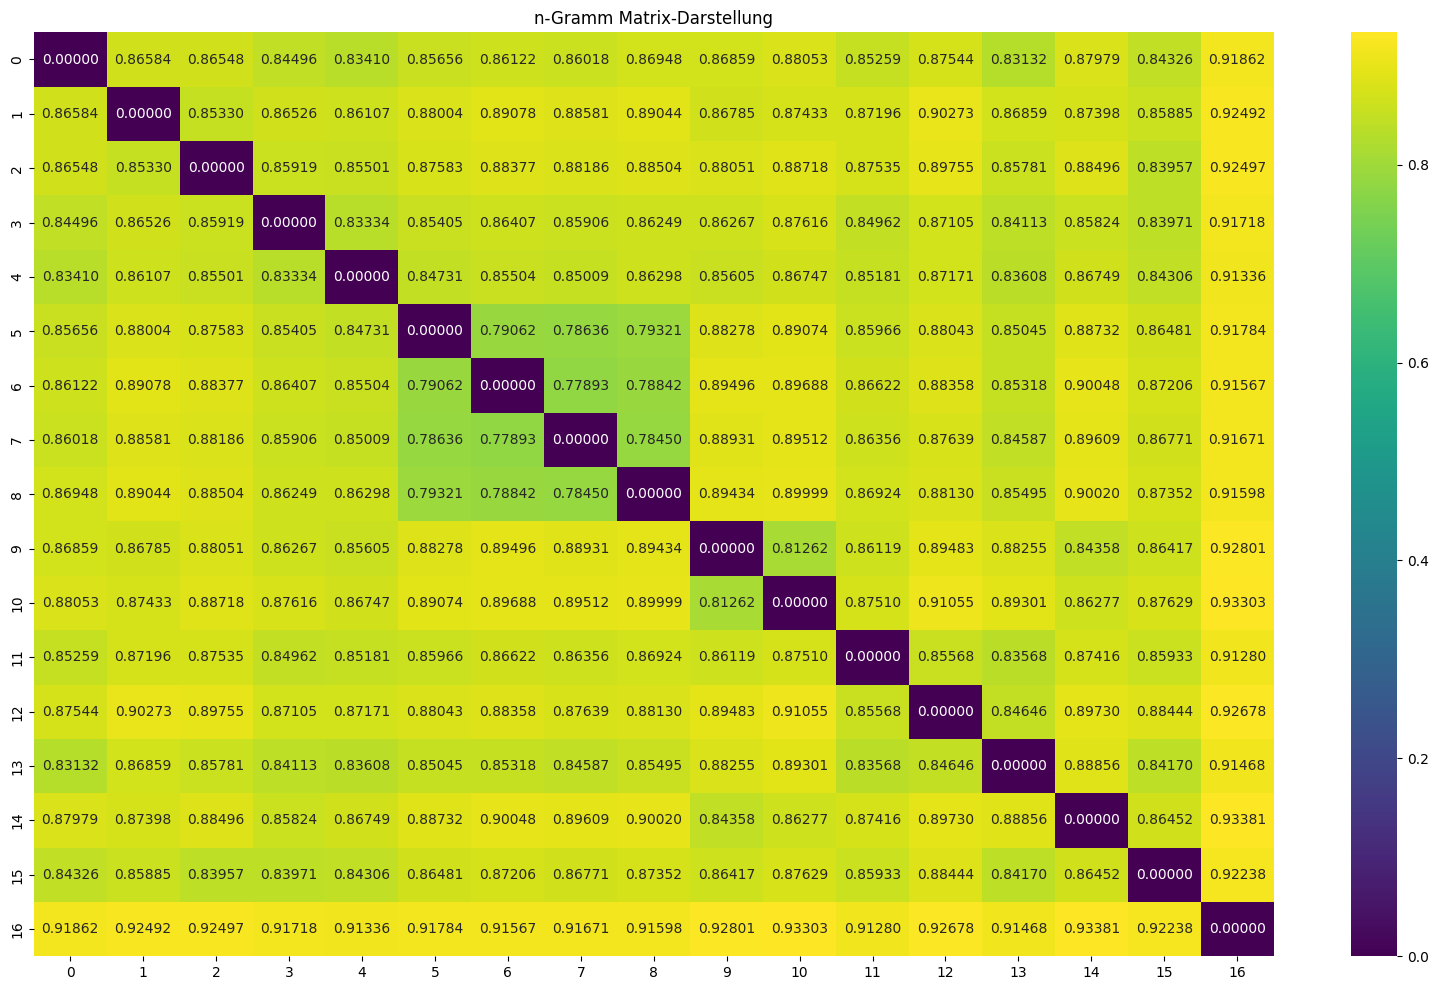

In [829]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.DataFrame(dist_matrix)

plt.figure(figsize=(20, 12))
sns.heatmap(df, annot=True, fmt=".5f", cmap="viridis")
plt.title("n-Gramm Matrix-Darstellung")
plt.show()


In [830]:
for text in corpus:

    nltk_text = Text(nltk.word_tokenize(text.lower())) #lower, damit es keine Doppelungen beim zählen später gibt
    #nltk_text_words = word_tokenize(text)
    
    wordcount = number_words(text)
    sentencescount = number_sentences(text)
    print(wordcount,sentencescount)

    avgsenlen = avg_sen_len(text) #average sentence length
    #print(avg_sen_len)
    avgwordlen = avg_word_len(text)
    #print(avg_word_len)
    #print(avgwordlen,avgsenlen)


    ttr_erg = round(ttr(nltk_text),2)
    avg_punct = punctuations(nltk_text)
    
    avg_syll = avg_syllables_per_word(text)
    fre_ger = flesch_reading_ease_ger(avgsenlen, avg_syll)
    wsf = wiener_sachtext_formel(text)
    print(avgwordlen, avgsenlen, avg_syll, wsf, ttr_erg)
    print(ngram_haeufigkeit(text))

    corpus_list.append([avgwordlen, avgsenlen, avg_syll, wsf, fre_ger, ttr_erg, round(avg_punct[0],3), round(avg_punct[1],3), round(avg_punct[2],3), round(avg_punct[3],3), round(avg_punct[4],3), round(avg_punct[5],3)]) #All Features
    #corpus_list.append([avgwordlen, avgsenlen, avg_syll, wsf, ttr_erg])
    corpus_name.append(nltk_text)

    print("-----------------------------------------------")

#print("Corpuslist:",corpus_list)

27616 1213
4.8 22.8 1.6 1.11 0.14
Anzahl eindeutiger Bigramme: 18890
Anzahl eindeutiger Trigramme: 28929

Top 5 Bigramme:
(',', 'und') → 336 Mal
(',', 'daß') → 194 Mal
(',', 'die') → 161 Mal
(',', 'als') → 107 Mal
(',', 'das') → 88 Mal

Top 5 Trigramme:
(',', 'daß', 'sie') → 68 Mal
('*', '*', '*') → 56 Mal
(',', 'als', 'sie') → 27 Mal
('.', 'ja', ',') → 24 Mal
(',', 'daß', 'er') → 22 Mal
None
-----------------------------------------------
54302 2749
5.3 19.8 1.7 0.72 0.17
Anzahl eindeutiger Bigramme: 41596
Anzahl eindeutiger Trigramme: 59601

Top 5 Bigramme:
('!', '“') → 433 Mal
(',', 'und') → 342 Mal
('“', '„') → 292 Mal
(',', 'die') → 257 Mal
(',', 'daß') → 220 Mal

Top 5 Trigramme:
('!', '“', '„') → 186 Mal
('*', '*', '*') → 132 Mal
('?', '“', '„') → 80 Mal
('.', '*', '*') → 38 Mal
(',', 'daß', 'die') → 34 Mal
None
-----------------------------------------------
63931 4079
5.5 15.7 1.8 0.18 0.15
Anzahl eindeutiger Bigramme: 46688
Anzahl eindeutiger Trigramme: 69058

Top 5 Bigramme:

In [831]:
corpus_list

[[4.8, 22.8, 1.6, 1.11, 100.3, 0.14, 0.003, 0.002, 0.033, 0.082, 0.011, 0.003],
 [5.3, 19.8, 1.7, 0.72, 103.4, 0.17, 0.017, 0.004, 0.03, 0.066, 0.004, 0.004],
 [5.5, 15.7, 1.8, 0.18, 107.6, 0.15, 0.032, 0.005, 0.029, 0.062, 0.002, 0.005],
 [5.0, 20.4, 1.7, 0.8, 102.8, 0.17, 0.01, 0.007, 0.029, 0.087, 0.002, 0.002],
 [4.9, 24.2, 1.6, 1.45, 98.9, 0.16, 0.007, 0.002, 0.032, 0.07, 0.006, 0.005],
 [5.4, 15.8, 1.8, 0.16, 107.5, 0.2, 0.001, 0.003, 0.051, 0.073, 0.0, 0.0],
 [5.5, 16.4, 1.8, 0.29, 106.9, 0.2, 0.001, 0.002, 0.049, 0.074, 0.0, 0.0],
 [5.4, 16.4, 1.8, 0.3, 106.9, 0.21, 0.001, 0.001, 0.051, 0.072, 0.0, 0.0],
 [5.5, 15.1, 1.8, 0.07, 108.2, 0.21, 0.001, 0.001, 0.054, 0.073, 0.0, 0.0],
 [4.8, 8.1, 1.5, -1.51, 114.9, 0.16, 0.03, 0.011, 0.059, 0.072, 0.008, 0.001],
 [5.1,
  13.6,
  1.7,
  -0.39,
  109.6,
  0.18,
  0.018,
  0.007,
  0.035,
  0.091,
  0.013,
  0.022],
 [5.1, 21.7, 1.7, 0.98, 101.5, 0.23, 0.002, 0.002, 0.036, 0.079, 0.021, 0.003],
 [5.0, 20.5, 1.7, 0.74, 102.7, 0.27, 0.007

In [832]:
corpus_vec = np.array(corpus_list)
corpus_matrix = cosine_distances(corpus_vec)

In [833]:
corpus_matrix = cosine_distances(corpus_vec)
corpus_matrix

array([[0.00000000e+00, 6.02068173e-04, 3.13138284e-03, 3.86240541e-04,
        1.42081338e-04, 3.04902401e-03, 2.57561763e-03, 2.57161671e-03,
        3.64748270e-03, 1.19767154e-02, 5.09236681e-03, 8.76014185e-05,
        3.58644604e-04, 3.10153534e-03, 7.92840696e-03, 2.13083942e-03,
        5.84623162e-03],
       [6.02068173e-04, 0.00000000e+00, 9.92322693e-04, 2.61757602e-05,
        1.31515393e-03, 9.47972818e-04, 6.90346509e-04, 6.89981150e-04,
        1.29247466e-03, 7.27423189e-03, 2.21719716e-03, 2.33171091e-04,
        3.43804573e-05, 6.38546658e-03, 4.20431646e-03, 4.75598705e-04,
        2.70824812e-03],
       [3.13138284e-03, 9.92322693e-04, 0.00000000e+00, 1.31927548e-03,
        4.58721679e-03, 1.11947301e-06, 2.75977235e-05, 2.79196388e-05,
        2.01000631e-05, 2.92217038e-03, 2.52865156e-04, 2.18536242e-03,
        1.37433857e-03, 1.23916244e-02, 1.12902911e-03, 9.84661510e-05,
        4.23077972e-04],
       [3.86240541e-04, 2.61757602e-05, 1.31927548e-03, 0.000

# Heatmap zeichnen

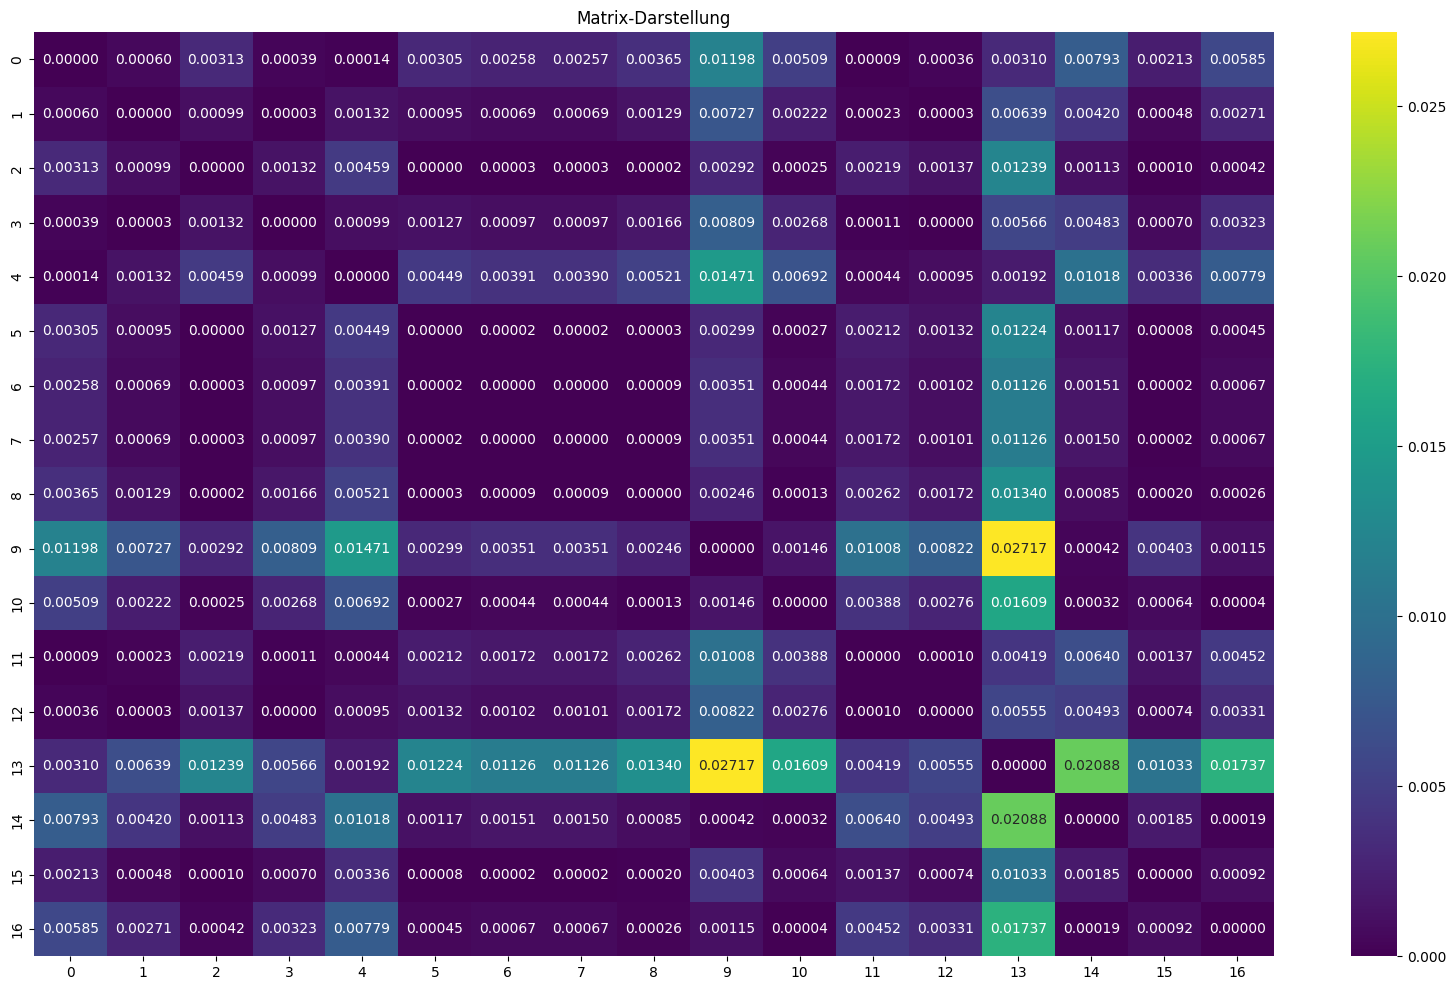

In [834]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.DataFrame(corpus_matrix)

plt.figure(figsize=(20, 12))
sns.heatmap(df, annot=True, fmt=".5f", cmap="viridis")
plt.title("Matrix-Darstellung")
plt.show()


-----------------------------------------------------------------

# Decision Tree

In [835]:
avgwordlen, avgsenlen, avg_syll, wsf, fre_ger, ttr_erg, round(avg_punct[0],3), round(avg_punct[1],3), round(avg_punct[2],3), round(avg_punct[3],3), round(avg_punct[4],3), round(avg_punct[5],3)

(5.6, 12.9, 2.0, -0.29, 110.6, 0.2, 0.0, 0.0, 0.057, 0.054, 0.005, 0.005)

In [836]:
colu = ['AverageWordLength', 'AverageSentenceLength', 'AverageSyllables', 'WienerSachtextFormel', 'FRE_Ger', 'TTR', 'Avg !', 'Avg ?', 'Avg .', 'Avg ,', 'Avg ;', 'Avg :']
corp = pd.DataFrame(corpus_list)
corp.columns = colu
corp

,AverageWordLength,AverageSentenceLength,AverageSyllables,WienerSachtextFormel,FRE_Ger,TTR,Avg !,Avg ?,Avg .,"Avg ,",Avg ;,Avg :
0,4.8,22.8,1.6,1.11,100.3,0.14,0.003,0.002,0.033,0.082,0.011,0.003
1,5.3,19.8,1.7,0.72,103.4,0.17,0.017,0.004,0.030,0.066,0.004,0.004
2,5.5,15.7,1.8,0.18,107.6,0.15,0.032,0.005,0.029,0.062,0.002,0.005
3,5.0,20.4,1.7,0.80,102.8,0.17,0.010,0.007,0.029,0.087,0.002,0.002
4,4.9,24.2,1.6,1.45,98.9,0.16,0.007,0.002,0.032,0.070,0.006,0.005
5,5.4,15.8,1.8,0.16,107.5,0.20,0.001,0.003,0.051,0.073,0.000,0.000
6,5.5,16.4,1.8,0.29,106.9,0.20,0.001,0.002,0.049,0.074,0.000,0.000
7,5.4,16.4,1.8,0.30,106.9,0.21,0.001,0.001,0.051,0.072,0.000,0.000
8,5.5,15.1,1.8,0.07,108.2,0.21,0.001,0.001,0.054,0.073,0.000,0.000
9,4.8,8.1,1.5,-1.51,114.9,0.16,0.030,0.011,0.059,0.072,0.008,0.001


In [837]:
corp["Author"]= ["aanrud", "achleitner", "achleitner", "alarcon", "alberti", "anonymous", "anonymous", "anonymous", "anonymous", "goethe", "goethe", "kafka", "kafka", "kafka", "schiller", "skowronnek", "westermann"]
corp

,AverageWordLength,AverageSentenceLength,AverageSyllables,WienerSachtextFormel,FRE_Ger,TTR,Avg !,Avg ?,Avg .,"Avg ,",Avg ;,Avg :,Author
0,4.8,22.8,1.6,1.11,100.3,0.14,0.003,0.002,0.033,0.082,0.011,0.003,aanrud
1,5.3,19.8,1.7,0.72,103.4,0.17,0.017,0.004,0.030,0.066,0.004,0.004,achleitner
2,5.5,15.7,1.8,0.18,107.6,0.15,0.032,0.005,0.029,0.062,0.002,0.005,achleitner
3,5.0,20.4,1.7,0.80,102.8,0.17,0.010,0.007,0.029,0.087,0.002,0.002,alarcon
4,4.9,24.2,1.6,1.45,98.9,0.16,0.007,0.002,0.032,0.070,0.006,0.005,alberti
5,5.4,15.8,1.8,0.16,107.5,0.20,0.001,0.003,0.051,0.073,0.000,0.000,anonymous
6,5.5,16.4,1.8,0.29,106.9,0.20,0.001,0.002,0.049,0.074,0.000,0.000,anonymous
7,5.4,16.4,1.8,0.30,106.9,0.21,0.001,0.001,0.051,0.072,0.000,0.000,anonymous
8,5.5,15.1,1.8,0.07,108.2,0.21,0.001,0.001,0.054,0.073,0.000,0.000,anonymous
9,4.8,8.1,1.5,-1.51,114.9,0.16,0.030,0.011,0.059,0.072,0.008,0.001,goethe


In [838]:
X = corp[colu] # Features
y = corp.Author # Target variable

In [839]:
# Split dataset into training set and test set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1) # 70% training and 30% test


In [840]:
# Create Decision Tree classifer object
clf = DecisionTreeClassifier()

# Train Decision Tree Classifer
clf = clf.fit(X_train,y_train)

#Predict the response for test dataset
y_pred = clf.predict(X_test)


In [841]:
# Model Accuracy, how often is the classifier correct?
print("Accuracy:",metrics.accuracy_score(y_test, y_pred))


Accuracy: 0.5


In [842]:
X = corp.iloc[:,0:12]
X

,AverageWordLength,AverageSentenceLength,AverageSyllables,WienerSachtextFormel,FRE_Ger,TTR,Avg !,Avg ?,Avg .,"Avg ,",Avg ;,Avg :
0,4.8,22.8,1.6,1.11,100.3,0.14,0.003,0.002,0.033,0.082,0.011,0.003
1,5.3,19.8,1.7,0.72,103.4,0.17,0.017,0.004,0.030,0.066,0.004,0.004
2,5.5,15.7,1.8,0.18,107.6,0.15,0.032,0.005,0.029,0.062,0.002,0.005
3,5.0,20.4,1.7,0.80,102.8,0.17,0.010,0.007,0.029,0.087,0.002,0.002
4,4.9,24.2,1.6,1.45,98.9,0.16,0.007,0.002,0.032,0.070,0.006,0.005
5,5.4,15.8,1.8,0.16,107.5,0.20,0.001,0.003,0.051,0.073,0.000,0.000
6,5.5,16.4,1.8,0.29,106.9,0.20,0.001,0.002,0.049,0.074,0.000,0.000
7,5.4,16.4,1.8,0.30,106.9,0.21,0.001,0.001,0.051,0.072,0.000,0.000
8,5.5,15.1,1.8,0.07,108.2,0.21,0.001,0.001,0.054,0.073,0.000,0.000
9,4.8,8.1,1.5,-1.51,114.9,0.16,0.030,0.011,0.059,0.072,0.008,0.001


In [843]:
y = corp.iloc[:,12]
y

0         aanrud
1     achleitner
2     achleitner
3        alarcon
4        alberti
5      anonymous
6      anonymous
7      anonymous
8      anonymous
9         goethe
10        goethe
11         kafka
12         kafka
13         kafka
14      schiller
15    skowronnek
16    westermann
Name: Author, dtype: object

In [844]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=10, test_size=0.2)

In [845]:
X_train.shape

(13, 12)

In [846]:
X_test.shape

(4, 12)

In [847]:
y_train.shape

(13,)

In [848]:
y_test.shape

(4,)

In [849]:
from sklearn.tree import DecisionTreeClassifier
dtc = DecisionTreeClassifier()

In [850]:
dtc.get_params()

{'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': None,
 'max_features': None,
 'max_leaf_nodes': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'random_state': None,
 'splitter': 'best'}

In [851]:
dtc.fit(X_train, y_train)

DecisionTreeClassifier()

In [852]:
y_pred = dtc.predict(X_test)

In [853]:
from sklearn.metrics import confusion_matrix, classification_report
print(confusion_matrix(y_test, y_pred))

[[0 0 0 1 0]
 [0 2 0 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]
 [0 0 1 0 0]]


In [854]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

     alarcon       0.00      0.00      0.00         1
   anonymous       1.00      1.00      1.00         2
      goethe       0.00      0.00      0.00         0
       kafka       0.00      0.00      0.00         0
    schiller       0.00      0.00      0.00         1

    accuracy                           0.50         4
   macro avg       0.20      0.20      0.20         4
weighted avg       0.50      0.50      0.50         4



c:\workspace\nlp-lernen\nlp-lernen\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\workspace\nlp-lernen\nlp-lernen\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\workspace\nlp-lernen\nlp-lernen\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\workspace\nlp-l

In [855]:
dtc.feature_importances_

array([0.09027778, 0.18298611, 0.        , 0.17303241, 0.        ,
       0.1625    , 0.        , 0.        , 0.13541667, 0.        ,
       0.09027778, 0.16550926])

In [856]:
X.columns

Index(['AverageWordLength', 'AverageSentenceLength', 'AverageSyllables',
       'WienerSachtextFormel', 'FRE_Ger', 'TTR', 'Avg !', 'Avg ?', 'Avg .',
       'Avg ,', 'Avg ;', 'Avg :'],
      dtype='object')

In [857]:
features = pd.DataFrame(dtc.feature_importances_, index=X.columns)
features

,0
AverageWordLength,0.090278
AverageSentenceLength,0.182986
AverageSyllables,0.000000
WienerSachtextFormel,0.173032
FRE_Ger,0.000000
TTR,0.162500
Avg !,0.000000
Avg ?,0.000000
Avg .,0.135417
"Avg ,",0.000000


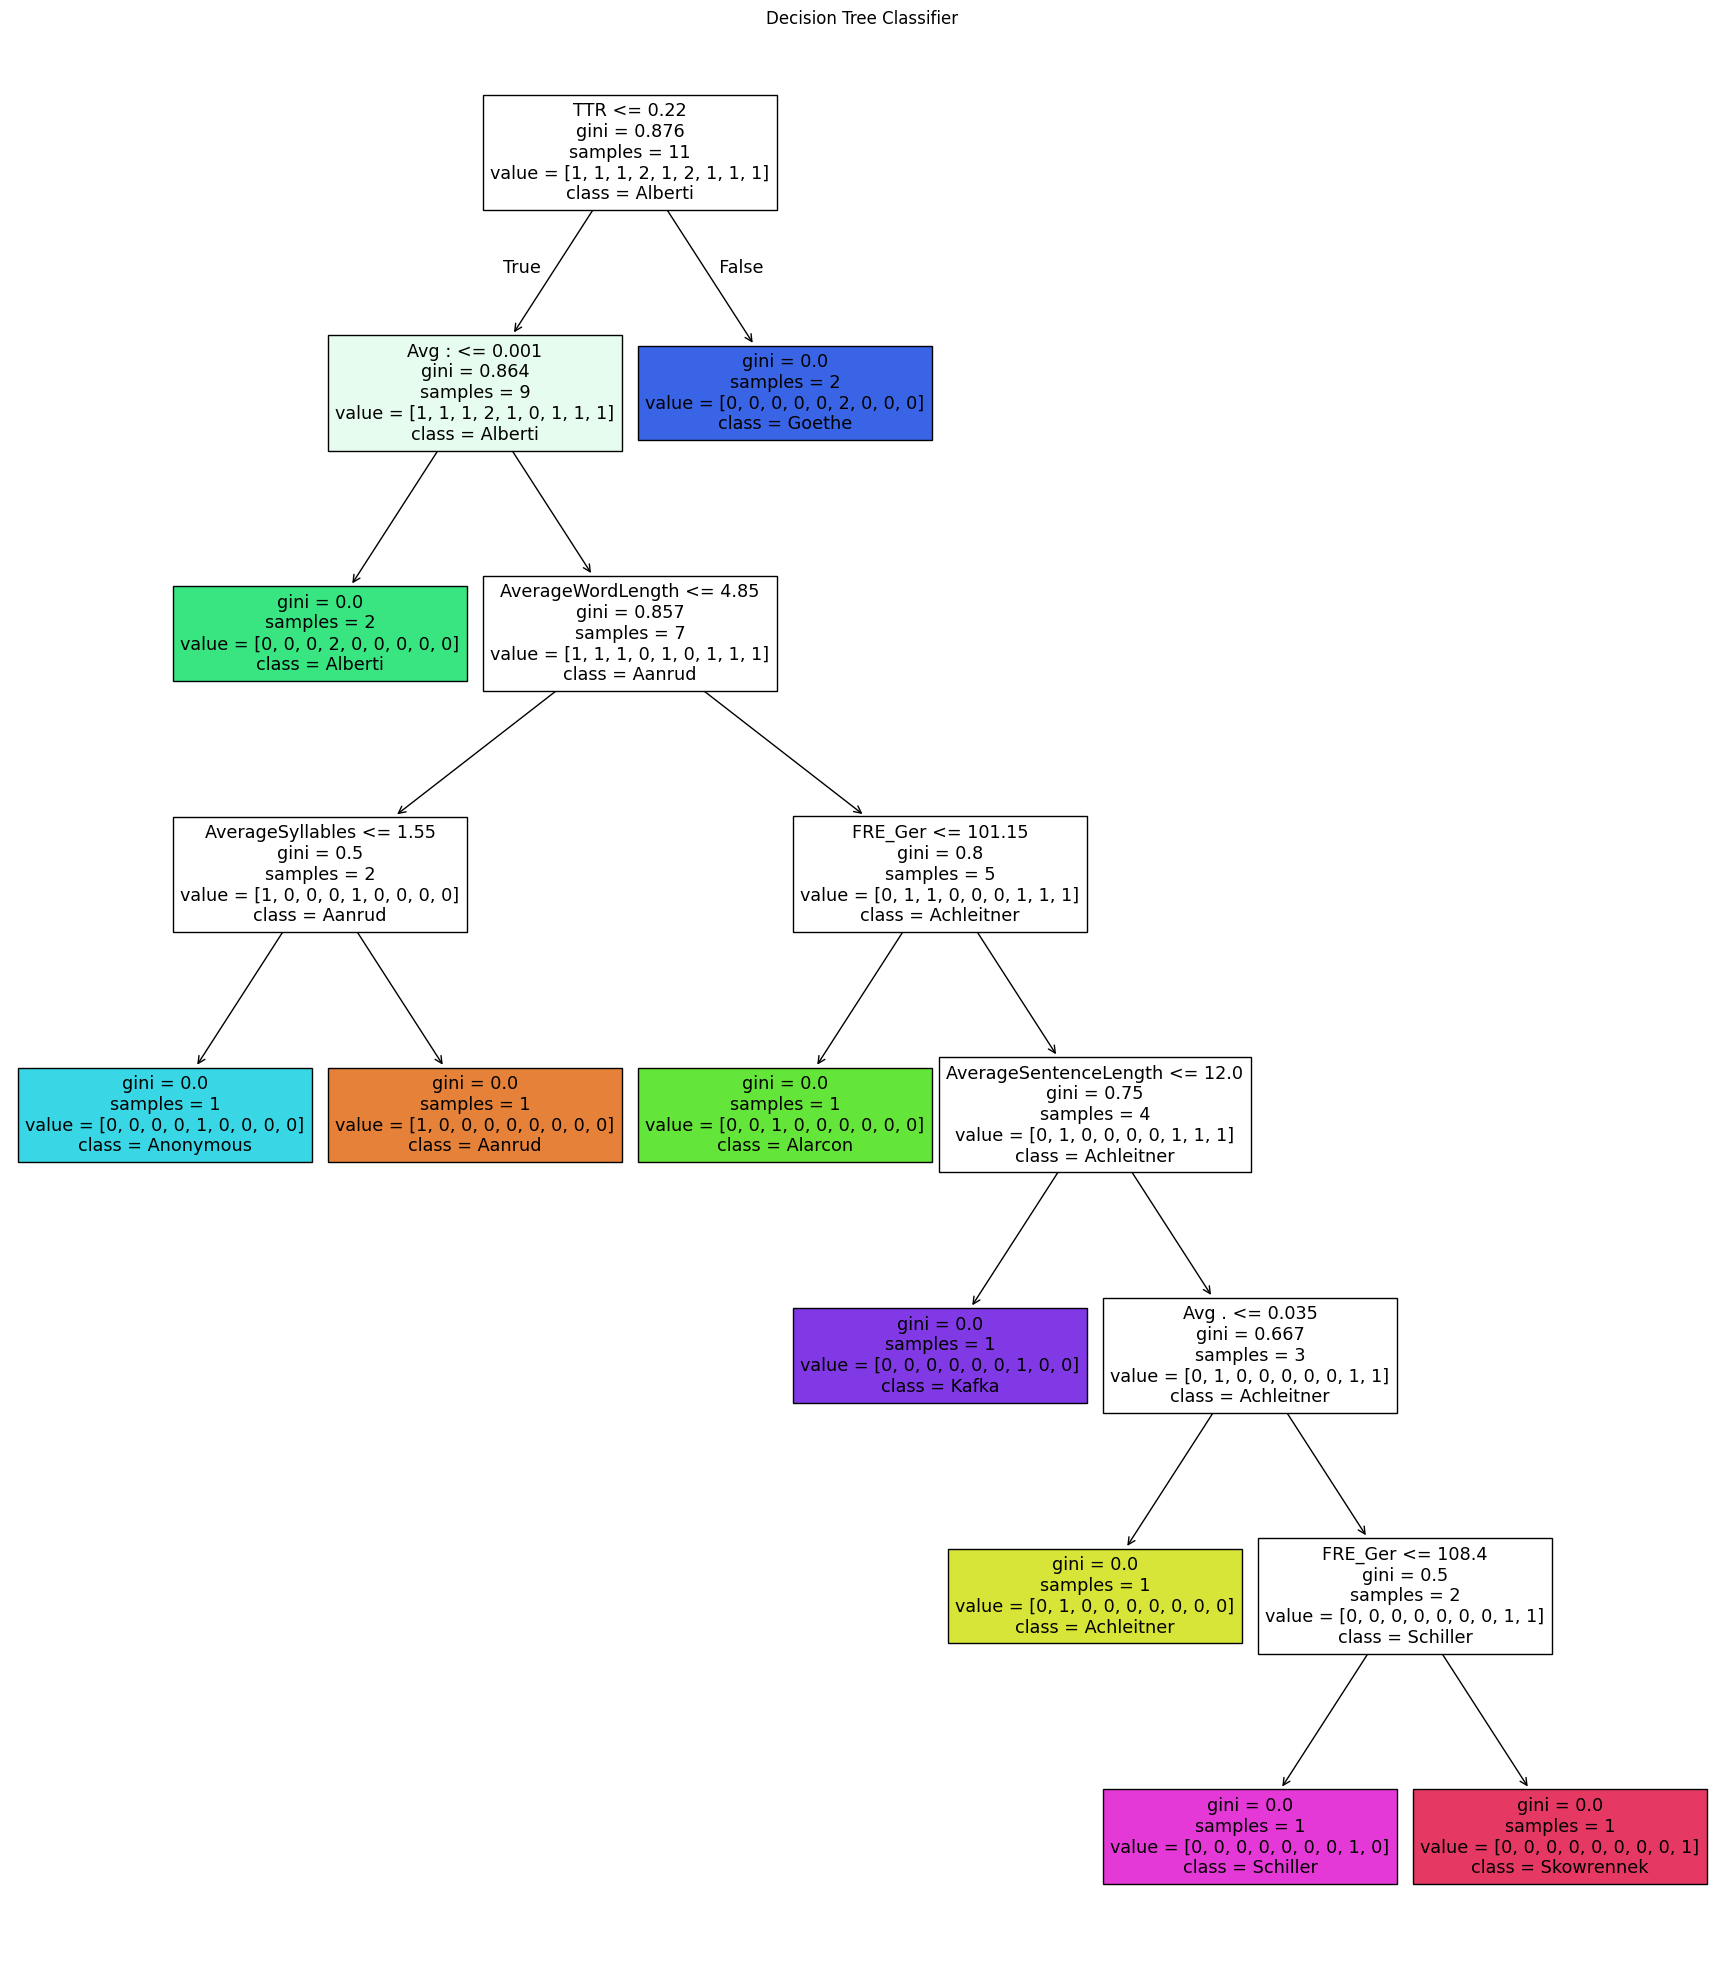

In [858]:
plt.figure(figsize=(22, 25))
tree.plot_tree(clf, filled=True, feature_names=X.columns, class_names=['Aanrud', 'Achleitner', 'Alarcon', 'Alberti', 'Anonymous', 'Goethe', 'Kafka', 'Schiller', 'Skowrennek', 'Westermann'])
plt.title("Decision Tree Classifier")
plt.show()


_______________________

# Random Forest

In [859]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.ensemble import RandomForestClassifier

In [860]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

classifier = RandomForestClassifier(n_estimators=1000, random_state=42)
classifier.fit(X_train, y_train)
y_pred = classifier.predict(X_test)

y_pred

array(['kafka', 'alarcon', 'anonymous', 'anonymous'], dtype=object)

In [861]:
y_test

0         aanrud
1     achleitner
5      anonymous
15    skowronnek
Name: Author, dtype: object

In [862]:
class_names=['Aanrud', 'Achleitner', 'Alarcon', 'Alberti', 'Anonymous', 'Goethe', 'Kafka', 'Schiller', 'Skowrennek', 'Westermann']

Accuracy: 25.00%


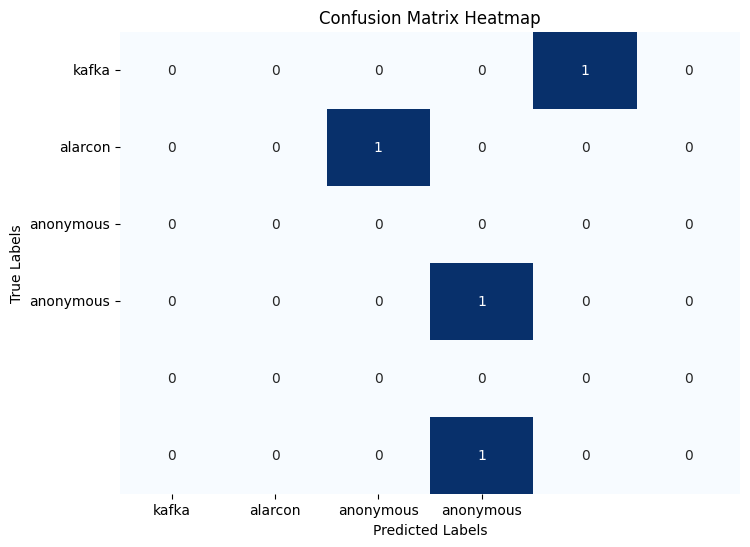

In [863]:
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy * 100:.2f}%')

conf_matrix = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='g', cmap='Blues', cbar=False, 
            xticklabels=y_pred, yticklabels=y_pred)

plt.title('Confusion Matrix Heatmap')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()

In [864]:
conf_matrix

array([[0, 0, 0, 0, 1, 0],
       [0, 0, 1, 0, 0, 0],
       [0, 0, 0, 0, 0, 0],
       [0, 0, 0, 1, 0, 0],
       [0, 0, 0, 0, 0, 0],
       [0, 0, 0, 1, 0, 0]])

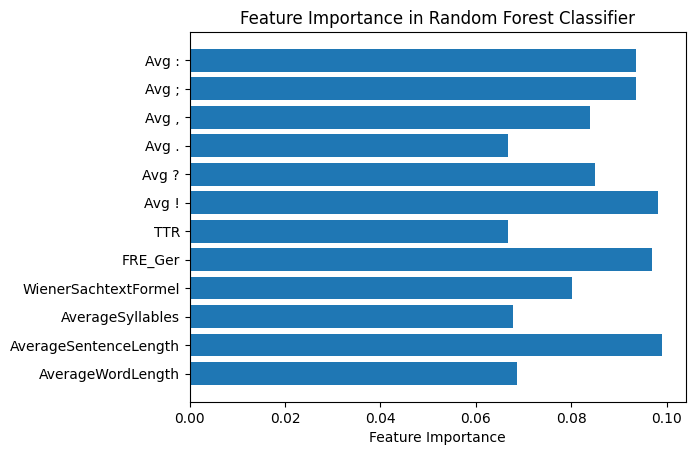

In [865]:
feature_importances = classifier.feature_importances_

plt.barh(X.columns, feature_importances)
plt.xlabel('Feature Importance')
plt.title('Feature Importance in Random Forest Classifier')
plt.show()

In [866]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

      aanrud       0.00      0.00      0.00         1
  achleitner       0.00      0.00      0.00         1
     alarcon       0.00      0.00      0.00         0
   anonymous       0.50      1.00      0.67         1
       kafka       0.00      0.00      0.00         0
  skowronnek       0.00      0.00      0.00         1

    accuracy                           0.25         4
   macro avg       0.08      0.17      0.11         4
weighted avg       0.12      0.25      0.17         4



c:\workspace\nlp-lernen\nlp-lernen\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\workspace\nlp-lernen\nlp-lernen\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\workspace\nlp-lernen\nlp-lernen\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\workspace\nlp-l

________________________

# Support Vector Machine

In [867]:
# Load the important packages
from sklearn.datasets import load_breast_cancer
import matplotlib.pyplot as plt
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.svm import SVC


In [868]:
X3 = X
y2 = y

In [869]:
X3

,AverageWordLength,AverageSentenceLength,AverageSyllables,WienerSachtextFormel,FRE_Ger,TTR,Avg !,Avg ?,Avg .,"Avg ,",Avg ;,Avg :
0,4.8,22.8,1.6,1.11,100.3,0.14,0.003,0.002,0.033,0.082,0.011,0.003
1,5.3,19.8,1.7,0.72,103.4,0.17,0.017,0.004,0.030,0.066,0.004,0.004
2,5.5,15.7,1.8,0.18,107.6,0.15,0.032,0.005,0.029,0.062,0.002,0.005
3,5.0,20.4,1.7,0.80,102.8,0.17,0.010,0.007,0.029,0.087,0.002,0.002
4,4.9,24.2,1.6,1.45,98.9,0.16,0.007,0.002,0.032,0.070,0.006,0.005
5,5.4,15.8,1.8,0.16,107.5,0.20,0.001,0.003,0.051,0.073,0.000,0.000
6,5.5,16.4,1.8,0.29,106.9,0.20,0.001,0.002,0.049,0.074,0.000,0.000
7,5.4,16.4,1.8,0.30,106.9,0.21,0.001,0.001,0.051,0.072,0.000,0.000
8,5.5,15.1,1.8,0.07,108.2,0.21,0.001,0.001,0.054,0.073,0.000,0.000
9,4.8,8.1,1.5,-1.51,114.9,0.16,0.030,0.011,0.059,0.072,0.008,0.001


In [870]:
X2 = X3.drop(X3.columns[2:], axis=1)
X2

,AverageWordLength,AverageSentenceLength
0,4.8,22.8
1,5.3,19.8
2,5.5,15.7
3,5.0,20.4
4,4.9,24.2
5,5.4,15.8
6,5.5,16.4
7,5.4,16.4
8,5.5,15.1
9,4.8,8.1


In [871]:
y2 = corp.iloc[:,12]
y2

0         aanrud
1     achleitner
2     achleitner
3        alarcon
4        alberti
5      anonymous
6      anonymous
7      anonymous
8      anonymous
9         goethe
10        goethe
11         kafka
12         kafka
13         kafka
14      schiller
15    skowronnek
16    westermann
Name: Author, dtype: object

In [872]:
X_train, X_test, y_train, y_test = train_test_split(X2, y2, random_state=33, test_size=0.2)

### ---> Checking beste combination out of Kernel, Gamma & Regression

In [873]:
model_reg0 = SVC(C=0.1)
model_reg0.fit(X_train, y_train)
model_reg0.score(X_train, y_train)

0.38461538461538464

In [874]:
model_reg1 = SVC(C=1.0)
model_reg1.fit(X_train, y_train)
model_reg1.score(X_train, y_train)

0.5384615384615384

In [875]:
model_reg2 = SVC(C=1000)
model_reg2.fit(X_train, y_train)
model_reg2.score(X_train, y_train)

0.9230769230769231

In [876]:
model_gamma0 = SVC(gamma=0.1)
model_gamma0.fit(X_train, y_train)
model_gamma0.score(X_train, y_train)

0.6153846153846154

In [877]:
model_gamma1 = SVC(gamma=1)
model_gamma1.fit(X_train, y_train)
model_gamma1.score(X_train, y_train)

0.7692307692307693

In [878]:
model_gamma2 = SVC(gamma=1000)
model_gamma2.fit(X_train, y_train)
model_gamma2.score(X_train, y_train)

1.0

In [879]:
model_linear = SVC(kernel="linear")
model_linear.fit(X_train, y_train)
model_linear.score(X_train, y_train)

0.6153846153846154

In [880]:
model_linear2 = SVC(kernel="rbf")
model_linear2.fit(X_train, y_train)
model_linear2.score(X_train, y_train)

0.5384615384615384

### Check completed <----

In [881]:
svm2 = SVC(kernel="linear", gamma=1000, C=1000)
svm2.fit(X_train, y_train)
svm2.score(X_train, y_train)

0.9230769230769231

In [882]:
color_map = {
    1: '#FF0000',   # red
    2: '#0000FF',   # blue
    3: '#008000',   # green
    4: '#FFA500',   # orange
    5: '#800080',   # purple
    6: '#FFFF00',   # yellow
    7: '#000000',   # black
    8: '#A2C523',   # lime green
    9: '#FF00FF',   # magenta
    10: "#48C5FF"   # sky blue
}

In [883]:
df_y2 = pd.DataFrame(y2)
werte = [1, 2, 2, 3, 4, 5, 5, 5, 5, 6, 6, 7, 7, 7, 8, 9, 10]
df_y2["Color"] = werte

In [884]:
df_y2['ColorName'] = df_y2['Color'].map(color_map)
df_y2

,Author,Color,ColorName
0,aanrud,1,#FF0000
1,achleitner,2,#0000FF
2,achleitner,2,#0000FF
3,alarcon,3,#008000
4,alberti,4,#FFA500
5,anonymous,5,#800080
6,anonymous,5,#800080
7,anonymous,5,#800080
8,anonymous,5,#800080
9,goethe,6,#FFFF00


In [885]:
from matplotlib.lines import Line2D
custom_legend = [
    Line2D([0], [0], marker='o', color='b', label='Aanrud', markerfacecolor='#FF0000', markersize=10),
    Line2D([0], [0], marker='o', color='b', label='Achleitner', markerfacecolor='#0000FF', markersize=10),
    Line2D([0], [0], marker='o', color='b', label='Alarcon', markerfacecolor='#008000', markersize=10),
    Line2D([0], [0], marker='o', color='b', label='Alberti', markerfacecolor='#FFA500', markersize=10),
    Line2D([0], [0], marker='o', color='b', label='Anonymous', markerfacecolor='#800080', markersize=10),
    Line2D([0], [0], marker='o', color='b', label='Goethe', markerfacecolor='#FFFF00', markersize=10),
    Line2D([0], [0], marker='o', color='b', label='Kafka', markerfacecolor='#000000', markersize=10),
    Line2D([0], [0], marker='o', color='b', label='Schiller', markerfacecolor='#A2C523', markersize=10),
    Line2D([0], [0], marker='o', color='b', label='Skowronnek', markerfacecolor='#FF00FF', markersize=10),
    Line2D([0], [0], marker='o', color='b', label='Westermann', markerfacecolor="#48C5FF", markersize=10)
]

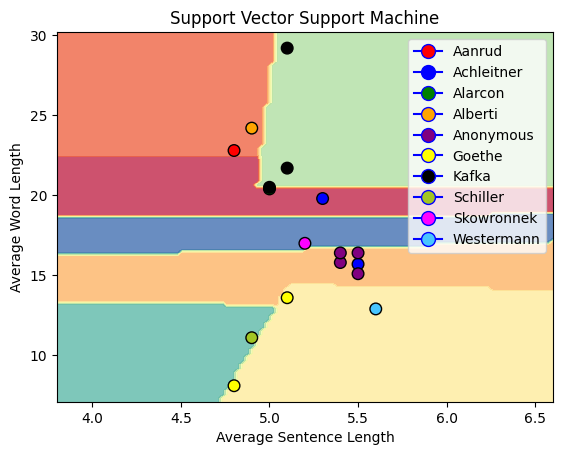

In [886]:
# Plot Decision Boundary
DecisionBoundaryDisplay.from_estimator(
        svm2,
        X2,
        response_method="predict",
        cmap=plt.cm.Spectral,
        alpha=0.8,
        xlabel=X2.columns[0],
        ylabel=X2.columns[1],
    )

# Scatter plot
#plt.figure(figsize=(10,26))
plt.title('Support Vector Support Machine')
plt.scatter(X2.iloc[:, 0], X2.iloc[:, 1], 
            c=df_y2['ColorName'], 
            s=70, edgecolors="k") #Alarcon liegt unter/hinter Kafka
plt.legend(handles=custom_legend)
plt.xlabel("Average Sentence Length")
plt.ylabel("Average Word Length")
#plt.colorbar()
plt.show()

### Multimodal Arrays

In [887]:
corp

,AverageWordLength,AverageSentenceLength,AverageSyllables,WienerSachtextFormel,FRE_Ger,TTR,Avg !,Avg ?,Avg .,"Avg ,",Avg ;,Avg :,Author
0,4.8,22.8,1.6,1.11,100.3,0.14,0.003,0.002,0.033,0.082,0.011,0.003,aanrud
1,5.3,19.8,1.7,0.72,103.4,0.17,0.017,0.004,0.030,0.066,0.004,0.004,achleitner
2,5.5,15.7,1.8,0.18,107.6,0.15,0.032,0.005,0.029,0.062,0.002,0.005,achleitner
3,5.0,20.4,1.7,0.80,102.8,0.17,0.010,0.007,0.029,0.087,0.002,0.002,alarcon
4,4.9,24.2,1.6,1.45,98.9,0.16,0.007,0.002,0.032,0.070,0.006,0.005,alberti
5,5.4,15.8,1.8,0.16,107.5,0.20,0.001,0.003,0.051,0.073,0.000,0.000,anonymous
6,5.5,16.4,1.8,0.29,106.9,0.20,0.001,0.002,0.049,0.074,0.000,0.000,anonymous
7,5.4,16.4,1.8,0.30,106.9,0.21,0.001,0.001,0.051,0.072,0.000,0.000,anonymous
8,5.5,15.1,1.8,0.07,108.2,0.21,0.001,0.001,0.054,0.073,0.000,0.000,anonymous
9,4.8,8.1,1.5,-1.51,114.9,0.16,0.030,0.011,0.059,0.072,0.008,0.001,goethe


In [888]:
X

,AverageWordLength,AverageSentenceLength,AverageSyllables,WienerSachtextFormel,FRE_Ger,TTR,Avg !,Avg ?,Avg .,"Avg ,",Avg ;,Avg :
0,4.8,22.8,1.6,1.11,100.3,0.14,0.003,0.002,0.033,0.082,0.011,0.003
1,5.3,19.8,1.7,0.72,103.4,0.17,0.017,0.004,0.030,0.066,0.004,0.004
2,5.5,15.7,1.8,0.18,107.6,0.15,0.032,0.005,0.029,0.062,0.002,0.005
3,5.0,20.4,1.7,0.80,102.8,0.17,0.010,0.007,0.029,0.087,0.002,0.002
4,4.9,24.2,1.6,1.45,98.9,0.16,0.007,0.002,0.032,0.070,0.006,0.005
5,5.4,15.8,1.8,0.16,107.5,0.20,0.001,0.003,0.051,0.073,0.000,0.000
6,5.5,16.4,1.8,0.29,106.9,0.20,0.001,0.002,0.049,0.074,0.000,0.000
7,5.4,16.4,1.8,0.30,106.9,0.21,0.001,0.001,0.051,0.072,0.000,0.000
8,5.5,15.1,1.8,0.07,108.2,0.21,0.001,0.001,0.054,0.073,0.000,0.000
9,4.8,8.1,1.5,-1.51,114.9,0.16,0.030,0.011,0.059,0.072,0.008,0.001


In [889]:
import numpy as np
print(type(X))
arr = np.array(X)

X_flattend = arr.reshape(102,2)
X_flattend

<class 'pandas.core.frame.DataFrame'>


array([[ 4.800e+00,  2.280e+01],
       [ 1.600e+00,  1.110e+00],
       [ 1.003e+02,  1.400e-01],
       [ 3.000e-03,  2.000e-03],
       [ 3.300e-02,  8.200e-02],
       [ 1.100e-02,  3.000e-03],
       [ 5.300e+00,  1.980e+01],
       [ 1.700e+00,  7.200e-01],
       [ 1.034e+02,  1.700e-01],
       [ 1.700e-02,  4.000e-03],
       [ 3.000e-02,  6.600e-02],
       [ 4.000e-03,  4.000e-03],
       [ 5.500e+00,  1.570e+01],
       [ 1.800e+00,  1.800e-01],
       [ 1.076e+02,  1.500e-01],
       [ 3.200e-02,  5.000e-03],
       [ 2.900e-02,  6.200e-02],
       [ 2.000e-03,  5.000e-03],
       [ 5.000e+00,  2.040e+01],
       [ 1.700e+00,  8.000e-01],
       [ 1.028e+02,  1.700e-01],
       [ 1.000e-02,  7.000e-03],
       [ 2.900e-02,  8.700e-02],
       [ 2.000e-03,  2.000e-03],
       [ 4.900e+00,  2.420e+01],
       [ 1.600e+00,  1.450e+00],
       [ 9.890e+01,  1.600e-01],
       [ 7.000e-03,  2.000e-03],
       [ 3.200e-02,  7.000e-02],
       [ 6.000e-03,  5.000e-03],
       [ 5

In [822]:
X_df = pd.DataFrame(X_flattend)
class_names2 = [(['Aanrud'] * 6) * 1 + (['Achleitner'] * 6) * 2 + (['Alarcon'] * 6) * 1 + (['Alberti'] * 6) * 1 + (['Anonymous'] * 6) * 4 +
               (['Goethe'] * 6) * 2 + (['Kafka'] * 6) * 3 + (['Schiller'] * 6) * 1 + (['Skowrennek'] * 6) * 1 + (['Westermann'] * 6) * 1]
class_names_multi = pd.DataFrame(class_names2[0])
color_codes2 = [(['#FF0000'] * 6) * 1 + (['#0000FF'] * 6) * 2 + (['#008000'] * 6) * 1 + (['#FFA500'] * 6) * 1 + (['#800080'] * 6) * 4 +
               (['#FFFF00'] * 6) * 2 + (['#000000'] * 6) * 3 + (['#A2C523'] * 6) * 1 + (['#FF00FF'] * 6) * 1 + (['#48C5FF'] * 6) * 1]
color_codes = pd.DataFrame(color_codes2[0])
class_names_multi["color"] = color_codes
class_names_multi

,0,color
0,Aanrud,#FF0000
1,Aanrud,#FF0000
2,Aanrud,#FF0000
3,Aanrud,#FF0000
4,Aanrud,#FF0000
...,...,...
97,Westermann,#48C5FF
98,Westermann,#48C5FF
99,Westermann,#48C5FF
100,Westermann,#48C5FF


In [798]:
X_train, X_test, y_train, y_test = train_test_split(X_flattend, class_names_multi[0], random_state=10, test_size=0.2)

In [816]:
svm2 = SVC(kernel="rbf", gamma=1000)
svm2.fit(X_train, y_train)
svm2.score(X_train, y_train)

0.6419753086419753

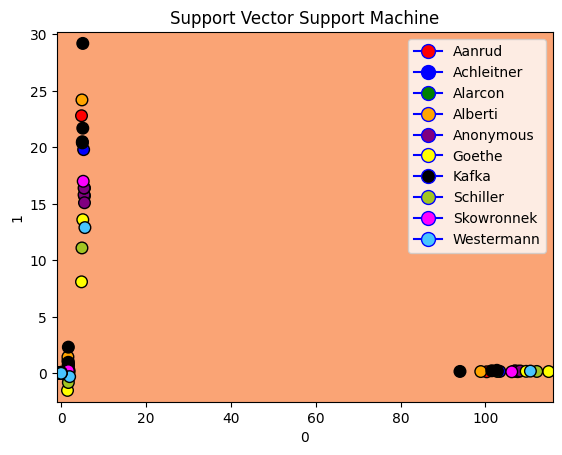

In [824]:
# Plot Decision Boundary
DecisionBoundaryDisplay.from_estimator(
        svm2,
        X_df,
        response_method="predict",
        cmap=plt.cm.Spectral,
        alpha=0.8,
        xlabel=X_df.columns[0],
        ylabel=X_df.columns[1],
    )

# Scatter plot
#plt.figure(figsize=(10,26))
plt.title('Support Vector Support Machine')
plt.scatter(X_df.iloc[:, 0], X_df.iloc[:, 1], 
            c=class_names_multi['color'], 
            s=70, edgecolors="k") #Alarcon liegt unter/hinter Kafka
plt.legend(handles=custom_legend)
#plt.xlabel("Average Sentence Length")
#plt.ylabel("Average Word Length")
#plt.colorbar()
plt.show()

In [893]:
print(classification_report(y_test, y_pred)) #ist das überhaupt richtig an dieser Stelle? 

              precision    recall  f1-score   support

      aanrud       0.00      0.00      0.00       1.0
  achleitner       0.00      0.00      0.00       1.0
     alarcon       0.00      0.00      0.00       0.0
   anonymous       0.00      0.00      0.00       1.0
       kafka       0.00      0.00      0.00       0.0
  westermann       0.00      0.00      0.00       1.0

    accuracy                           0.00       4.0
   macro avg       0.00      0.00      0.00       4.0
weighted avg       0.00      0.00      0.00       4.0



c:\workspace\nlp-lernen\nlp-lernen\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\workspace\nlp-lernen\nlp-lernen\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\workspace\nlp-lernen\nlp-lernen\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\workspace\nlp-l

In [801]:
model_reg0 = SVC(C=0.1)
model_reg0.fit(X_train, y_train)
model_reg0.score(X_train, y_train)

0.2345679012345679

In [802]:
model_reg1 = SVC(C=1.0)
model_reg1.fit(X_train, y_train)
model_reg1.score(X_train, y_train)

0.24691358024691357

In [803]:
model_reg2 = SVC(C=1000)
model_reg2.fit(X_train, y_train)
model_reg2.score(X_train, y_train)

0.345679012345679

In [804]:
model_gamma0 = SVC(gamma=0.1)
model_gamma0.fit(X_train, y_train)
model_gamma0.score(X_train, y_train)

0.3333333333333333

In [805]:
model_gamma1 = SVC(gamma=1)
model_gamma1.fit(X_train, y_train)
model_gamma1.score(X_train, y_train)

0.4567901234567901

In [818]:
model_gamma2 = SVC(gamma=1000)
model_gamma2.fit(X_train, y_train)
model_gamma2.score(X_train, y_train)

0.6419753086419753

In [807]:
model_linear = SVC(kernel="linear")
model_linear.fit(X_train, y_train)
model_linear.score(X_train, y_train)

0.2345679012345679

In [808]:
model_linear2 = SVC(kernel="rbf")
model_linear2.fit(X_train, y_train)
model_linear2.score(X_train, y_train)

0.24691358024691357